# 06 - Conformance checking

Do patients follow the **expected sepsis pathway**? Two views are used, both on the clinical-steps log (repeated lab tests left out):

- **Formal check:** every patient is aligned to an expected process model. The alignment gives a **fitness** score (1.0 = follows the model exactly) and lists the steps that are *missing* or *unexpected*.
- **Rule-based checks:** simple yes/no questions that explain the deviations (no antibiotics, late antibiotics, no discharge, ...).

> **Assumption:** the expected pathway is built from the standard route found in the data and the usual sepsis care sequence. It should be confirmed with the mentor. Changing it changes the numbers (`EXPECTED_PATHWAY` in `src/conformance.py`).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent
sys.path.append(str(ROOT / 'src'))

from conformance import (EXPECTED_PATHWAY, RULES, check_conformance, deviation_summary, deviation_patterns, load_log)
from plot_style import apply_style, save_fig, BLUE, INK, INK_SECONDARY
from prepare_log import load_cases

apply_style()
table = check_conformance(load_log())
cases = load_cases()
n = len(table)
print('Expected pathway (process-tree notation):')
print(EXPECTED_PATHWAY)

aligning log, completed variants ::   0%|          | 0/152 [00:00<?, ?it/s]

Expected pathway (process-tree notation):
->( 'ER Registration', 'ER Triage', 'ER Sepsis Triage', +( X('IV Liquid', tau), 'IV Antibiotics' ), X( 'Admission NC', ->('Admission IC', 'Admission NC') ), X('Release A', 'Release B', 'Release C', 'Release D', 'Release E'), X('Return ER', tau) )


## 1. Headline numbers

In [2]:
pd.Series({
    'Patients checked': n,
    'Follow the expected pathway exactly': f"{int(table['conforms'].sum())} ({table['conforms'].mean() * 100:.1f}%)",
    'Average fitness': round(table['fitness'].mean(), 3),
    'Lowest fitness': round(table['fitness'].min(), 2),
}, name='value').to_frame()

,value
Patients checked,995
Follow the expected pathway exactly,329 (33.1%)
Average fitness,0.896
Lowest fitness,0.6


## 2. How closely do patients follow the pathway?
Fitness per patient, in groups. 1.0 means the patient follows the expected pathway exactly.

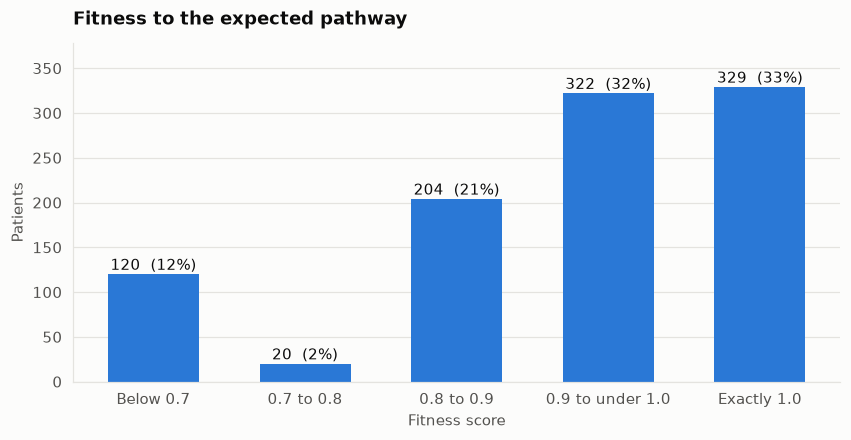

In [3]:
bins = [0, 0.7, 0.8, 0.9, 0.9999999, 1.01]
labels = ['Below 0.7', '0.7 to 0.8', '0.8 to 0.9', '0.9 to under 1.0', 'Exactly 1.0']
groups = pd.cut(table['fitness'], bins=bins, labels=labels, right=False).value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(groups.index, groups.values, color=BLUE, width=0.6)
ax.grid(axis='x', visible=False)
for i, v in enumerate(groups.values):
    ax.text(i, v + groups.max() * 0.015, f'{v}  ({v / n * 100:.0f}%)', ha='center', color=INK, fontsize=10)
ax.set_ylim(0, groups.max() * 1.15)
ax.set_title('Fitness to the expected pathway')
ax.set_ylabel('Patients')
ax.set_xlabel('Fitness score')
save_fig(fig, 'conformance_fitness')
plt.show()

## 3. Which deviations are most common?
Share of all 995 patients. A patient can have several deviations, so the bars add up to more than 100%.

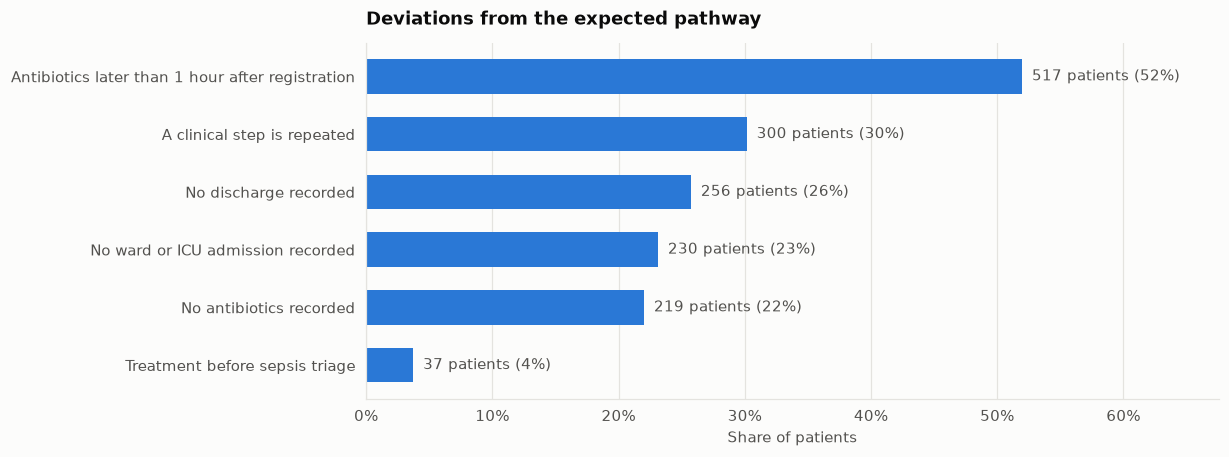

,deviation,cases,share_pct
1,Antibiotics later than 1 hour after registration,517,52.0
2,A clinical step is repeated,300,30.2
3,No discharge recorded,256,25.7
4,No ward or ICU admission recorded,230,23.1
5,No antibiotics recorded,219,22.0
6,Treatment before sepsis triage,37,3.7


In [4]:
rules = deviation_summary(table).query("kind == 'rule'").sort_values('share_pct')

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(rules['deviation'], rules['share_pct'], color=BLUE, height=0.6)
ax.grid(axis='y', visible=False)
for i, (c, p) in enumerate(zip(rules['cases'], rules['share_pct'])):
    ax.text(p + 0.8, i, f'{c} patients ({p:.0f}%)', va='center', color=INK_SECONDARY, fontsize=10)
ax.set_xlim(0, rules['share_pct'].max() * 1.3)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_title('Deviations from the expected pathway')
ax.set_xlabel('Share of patients')
save_fig(fig, 'conformance_deviations')
plt.show()
rules.sort_values('cases', ascending=False)[['deviation', 'cases', 'share_pct']].round(1)

## 4. The most common deviation patterns
Combinations of steps that are *missing* (expected but not recorded) and *extra* (recorded but not expected).

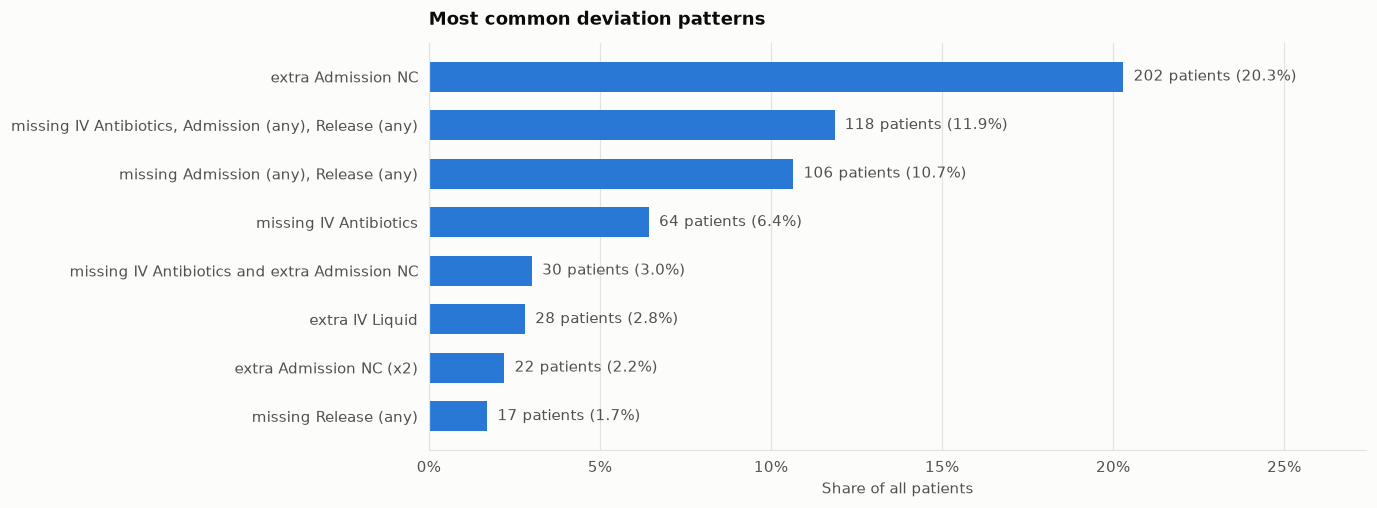

,description,cases,share_of_all_pct
0,extra Admission NC,202,20.3
1,"missing IV Antibiotics, Admission (any), Relea...",118,11.9
2,"missing Admission (any), Release (any)",106,10.7
3,missing IV Antibiotics,64,6.4
4,missing IV Antibiotics and extra Admission NC,30,3.0
5,extra IV Liquid,28,2.8
6,extra Admission NC (x2),22,2.2
7,missing Release (any),17,1.7


In [5]:
patterns = deviation_patterns(table, top=8).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(patterns['description'], patterns['share_of_all_pct'], color=BLUE, height=0.62)
ax.grid(axis='y', visible=False)
for i, (c, p) in enumerate(zip(patterns['cases'], patterns['share_of_all_pct'])):
    ax.text(p + 0.3, i, f'{c} patients ({p:.1f}%)', va='center', color=INK_SECONDARY, fontsize=10)
ax.set_xlim(0, patterns['share_of_all_pct'].max() * 1.35)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_title('Most common deviation patterns')
ax.set_xlabel('Share of all patients')
save_fig(fig, 'conformance_patterns')
plt.show()
patterns.iloc[::-1][['description', 'cases', 'share_of_all_pct']].round(1)

## 5. Timing is outside the formal check
The expected model checks the *order* of steps, not how long they take. Patients can follow the sequence exactly and still be treated late.

In [6]:
treated = table[~table['no_antibiotics']]
exact = table[table['conforms']]
pd.Series({
    'Patients with antibiotics recorded': len(treated),
    'of these, later than 1 hour after registration': f"{int(treated['late_antibiotics'].sum())} ({treated['late_antibiotics'].mean() * 100:.1f}%)",
    'Patients following the pathway exactly': len(exact),
    'of these, antibiotics later than 1 hour': f"{int(exact['late_antibiotics'].sum())} ({exact['late_antibiotics'].mean() * 100:.1f}%)",
    'Treatment before sepsis triage': f"{int(table['treated_before_sepsis_triage'].sum())} ({table['treated_before_sepsis_triage'].mean() * 100:.1f}%)",
}, name='value').to_frame()

,value
Patients with antibiotics recorded,776
"of these, later than 1 hour after registration",517 (66.6%)
Patients following the pathway exactly,329
"of these, antibiotics later than 1 hour",212 (64.4%)
Treatment before sepsis triage,37 (3.7%)


## 6. Who follows the pathway?
Share of patients following the expected pathway exactly, by age group and by whether they returned to the ER. These are descriptions, not explanations.

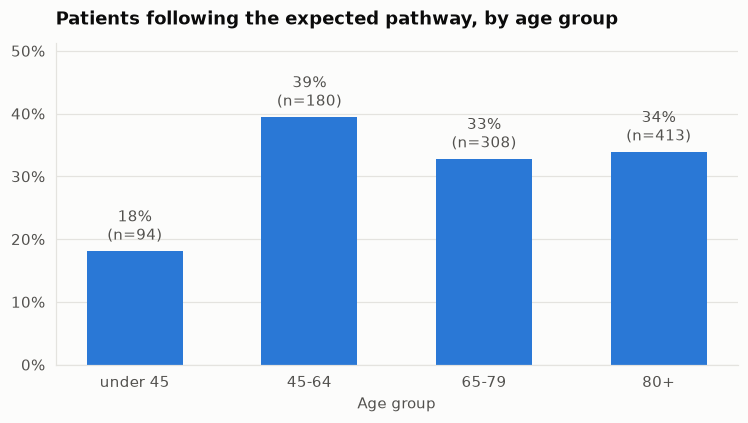

,% following the pathway
returned_to_er,
did not return,27.5
returned,47.5


In [7]:
merged = table.merge(cases[['case:concept:name', 'age_group', 'returned_to_er']], on='case:concept:name')
order = ['under 45', '45-64', '65-79', '80+']
by_age = merged.groupby('age_group')['conforms'].agg(['mean', 'size']).reindex(order)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(by_age.index, by_age['mean'] * 100, color=BLUE, width=0.55)
ax.grid(axis='x', visible=False)
for i, (m, s) in enumerate(zip(by_age['mean'], by_age['size'])):
    ax.text(i, m * 100 + 1, f'{m * 100:.0f}%\n(n={s})', ha='center', va='bottom', color=INK_SECONDARY, fontsize=10)
ax.set_ylim(0, by_age['mean'].max() * 100 * 1.3)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_title('Patients following the expected pathway, by age group')
ax.set_xlabel('Age group')
save_fig(fig, 'conformance_by_age')
plt.show()
merged.groupby('returned_to_er')['conforms'].mean().mul(100).round(1).rename({False: 'did not return', True: 'returned'}).to_frame('% following the pathway')

## Findings
- **33% of patients (329 of 995) follow the expected pathway exactly.** The average fitness is 0.90, so most patients follow most of it.
- **Most deviations are missing steps, not wrong order.** 256 patients (26%) have no discharge, 230 (23%) no admission and 219 (22%) no antibiotics. These overlap: 118 patients stop after sepsis triage, so they miss antibiotics, admission and discharge together.
- **The largest single pattern is an extra ward record.** 202 patients (20%) miss nothing but have an additional `Admission NC` event. This is the repeated ward record flagged earlier, and it is the focus of the rework analysis that comes next.
- **The order of steps is mostly respected.** Only 37 patients (4%) are treated before sepsis triage.
- **Timing is a separate issue.** Of the 776 patients who received antibiotics, 517 (67%) received them more than 1 hour after registration, and this also holds for most of the patients who follow the pathway exactly. The formal check looks at order, not speed.
- **Who follows the pathway.** Patients under 45 follow it least often (18%, n=94), against 33% to 39% in the older groups. Patients who returned to the ER follow it more often (47.5% against 27.5%), because a return requires a recorded discharge. These are descriptions, not explanations.
- **Limits.** The expected pathway is an assumption and must be confirmed with the mentor; a different definition gives different numbers. Four patients deviate in ways the plain rules do not name.
- **Next step:** study the repeated steps and loops (rework analysis).
